## Context

This notebook accompanies User Guide section 17 (Behavioral Contracts). It builds the three risk-tier contracts — advisory, recommendation, action-taking — and validates one valid sequence and two failure modes against each. The visualization is a `(contract, state)` visited-states grid, so the reader can see at a glance which states each contract reached. The final assertion confirms that the action-taking contract rejects a sequence that omits `diagnose_fairness`.

In [ ]:
# Phase 1B preamble: bootstrap runtime + load shared helpers
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()  # stubs modeva if absent
from tutorials.user_guide.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')
from tutorials.user_guide.notebooks import _helpers_phase4a as h4a


### Concept: structural enforcement via FSM

A behavioral contract is a finite-state machine (FSM) whose states correspond to workflow milestones (`data_loaded`, `preprocessed`, `model_trained`, `diagnosed`, `fair_checked`, `compared`, `deployment_ready`, `human_review`) and whose transitions are the only legal moves. Tool permissions are scoped to each state so that a tool runs only when the FSM is in a state that explicitly permits it. A missing transition cannot be taken — the enforcement is structural, not probabilistic.

Three factories ship in `governed_agent/behaviors/contracts.py`. `advisory_contract()` is loose: 50-call budget, no fairness or human-review gate. `recommendation_contract()` is standard: 30-call budget with a `_invariant_no_train_without_preprocess` invariant. `action_taking_contract()` is strict: 20-call budget on a single linear path through `idle → data_loaded → preprocessed → model_trained → diagnosed → fair_checked → compared → human_review → deployment_ready`, with mandatory `diagnose_robustness` and `diagnose_fairness` invariants and a human-approval gate before deployment.

`ProcessEvaluator.validate_sequence` walks the FSM tool-by-tool, enforcing permissions, transitions, the budget, and all invariants. The verdict is structural and deterministic; replaying the same sequence always yields the same `SequenceValidation`.

In [ ]:
from knowlytix.harness.governance.behaviors.contracts import (
    ProcessEvaluator,
    advisory_contract, recommendation_contract,
    action_taking_contract,
)

advisory       = advisory_contract()
recommendation = recommendation_contract()
action_taking  = action_taking_contract()

for c in (advisory, recommendation, action_taking):
    print(f'{c.name:18s}'
          f' budget={c.max_tool_calls:2d}'
          f' invariants={len(c.invariants)}'
          f' human_approval={c.require_human_approval}')


### Verifying the contract budgets

The numbers below are taken verbatim from the factory functions in `governed_agent/behaviors/contracts.py` so that this notebook fails loudly if those defaults drift.

In [3]:
assert advisory.max_tool_calls == 50, (
    'advisory budget changed in source: '
    f'expected 50, got {advisory.max_tool_calls}'
)
assert recommendation.max_tool_calls == 30, (
    'recommendation budget changed in source: '
    f'expected 30, got {recommendation.max_tool_calls}'
)
assert action_taking.max_tool_calls == 20, (
    'action_taking budget changed in source: '
    f'expected 20, got {action_taking.max_tool_calls}'
)
assert action_taking.require_human_approval is True
print('OK: budgets and human_approval flag match source.')


OK: budgets and human_approval flag match source.


### Three sequences across three contracts

We define three sequences:

- **valid**: a fully compliant action-taking flow that passes preprocessing, training, robustness check, fairness check, comparison, human review, and reaches deployment.
- **missing fairness**: identical except `diagnose_fairness` is omitted, so the action-taking contract should reject it (either via the FSM transition table — once in DIAGNOSED only diagnose_fairness is permitted — or via the `_invariant_no_deploy_without_fairness` invariant).
- **over budget**: 25 tool calls with no preprocessing, designed to blow past both the recommendation budget (30) for advisory and the action-taking budget (20).

In [4]:
valid_sequence = [
    'load_dataset', 'preprocess_data', 'train_model',
    'diagnose_robustness', 'diagnose_fairness',
    'leaderboard',
]
missing_fairness = [
    'load_dataset', 'preprocess_data', 'train_model',
    'diagnose_robustness', 'leaderboard',
    'leaderboard',
]
over_budget = (['recall_memory'] * 25)

sequences = [
    ('valid',            valid_sequence),
    ('missing_fairness', missing_fairness),
    ('over_budget',      over_budget),
]
for label, s in sequences:
    print(f'{label:18s} len={len(s):3d}  '
          f'first={s[:3]} ...')


valid              len=  6  first=['load_dataset', 'preprocess_data', 'train_model'] ...
missing_fairness   len=  6  first=['load_dataset', 'preprocess_data', 'train_model'] ...
over_budget        len= 25  first=['recall_memory', 'recall_memory', 'recall_memory'] ...


In [5]:
# Validate each sequence against each contract.
results = {}
for cname, contract in [('advisory', advisory),
                        ('recommendation', recommendation),
                        ('action_taking', action_taking)]:
    ev = ProcessEvaluator(contract)
    for label, seq in sequences:
        v = ev.validate_sequence(seq)
        results[(cname, label)] = v
        flag = 'OK ' if v.valid else 'BAD'
        print(f'{flag}  {cname:14s} / {label:18s}'
              f'  checked={v.tools_checked:2d}'
              f'  blocked={v.tools_blocked:2d}'
              f'  states={len(v.states_visited)}')


OK   advisory       / valid               checked= 6  blocked= 0  states=7
OK   advisory       / missing_fairness    checked= 6  blocked= 0  states=6
OK   advisory       / over_budget         checked=25  blocked= 0  states=1
OK   recommendation / valid               checked= 6  blocked= 0  states=7
OK   recommendation / missing_fairness    checked= 6  blocked= 0  states=6
OK   recommendation / over_budget         checked=25  blocked= 0  states=1
OK   action_taking  / valid               checked= 6  blocked= 0  states=7
BAD  action_taking  / missing_fairness    checked= 6  blocked= 2  states=5
BAD  action_taking  / over_budget         checked=25  blocked= 5  states=1


### Visualization: visited-states overlay per contract

The grid below shows which FSM states each contract reached when validating the *valid* sequence. The advisory contract reaches the most states because its transition table is loose; the action-taking contract reaches a strict linear sequence ending in `deployment_ready` only after passing every gate.

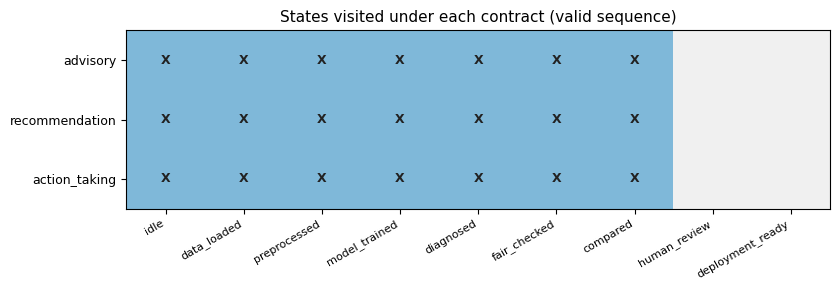

In [6]:
import matplotlib.pyplot as plt

rows_for_grid = []
for cname in ('advisory', 'recommendation', 'action_taking'):
    v = results[(cname, 'valid')]
    visited = [s.value for s in v.states_visited]
    rows_for_grid.append((cname, visited))

fig, ax = plt.subplots(figsize=(8.5, 3.0))
h4a.plot_visited_states_grid(
    ax, rows_for_grid,
    title='States visited under each contract '
          '(valid sequence)',
)
fig.tight_layout()
plt.show()


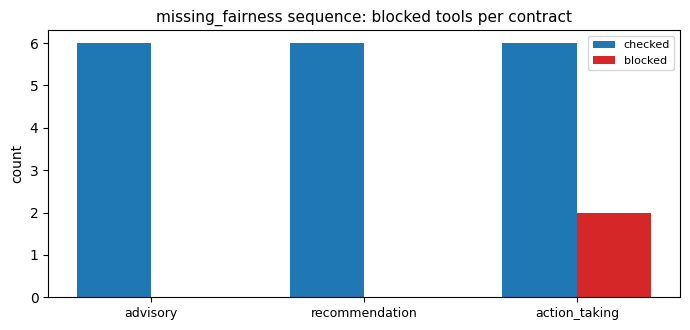

In [7]:
# Second visualization: tools checked vs blocked per
# contract for the missing-fairness sequence. This is
# the most informative comparison because the same
# sequence yields different verdicts under different
# risk tiers.
labels   = ['advisory', 'recommendation', 'action_taking']
checked  = [results[(c, 'missing_fairness')].tools_checked
            for c in labels]
blocked  = [results[(c, 'missing_fairness')].tools_blocked
            for c in labels]
fig, ax = plt.subplots(figsize=(7.0, 3.4))
h4a.plot_contract_validity_bar(
    ax, labels, checked, blocked,
    title='missing_fairness sequence: blocked tools '
          'per contract',
)
fig.tight_layout()
plt.show()


### Exercises

1. Construct a sequence that reaches `deployment_ready` under the action-taking contract without passing through `human_review`. Confirm `v.valid is False` and that the violation message names the missing `human_review` step.
2. Read `recommendation.transitions[ContractState.PREPROCESSED]` and identify the only state that the recommendation contract permits to follow `PREPROCESSED`. How does this differ from the advisory contract?
3. Compare `v.invariant_violations` between the missing-fairness sequence and the over-budget sequence. Which violation type wins when both are triggered?

### What you should now be able to do

- Build all three risk-tier contracts via their factories.
- Validate a tool sequence against a contract using `ProcessEvaluator.validate_sequence` and read the resulting `SequenceValidation`.
- Recognise which contract gates a call: the transition table, the per-state tool permission table, the budget, or an invariant.
- Distinguish the action-taking contract (strict linear path with mandatory fairness + robustness + human review) from the advisory contract (loose transition graph with no invariants).

### Cross-references

- USER_GUIDE.md section 17 (Behavioral Contracts)
- USER_GUIDE.md section 16 (Governed Tool Gateway) — the gate-2 policy check that complements behavioral contracts at the call site
- `governed_agent/behaviors/contracts.py` — source of truth for the FSM, tool permissions, and invariants
- `gms_agent_builder_ext/chapters/ch13.tex` — chapter-form treatment with the same FSM

In [8]:
# Final assertion: the action_taking contract rejects
# a sequence that omits diagnose_fairness. This is the
# load-bearing claim of behavioral contracts: a
# fairness-mandatory tier cannot reach deployment
# without diagnose_fairness in the trail.
v_at_missing = results[('action_taking',
                        'missing_fairness')]
assert v_at_missing.valid is False, (
    'action_taking must reject missing-fairness '
    'sequence; got valid=True'
)
# Confirm at least one violation references either the
# diagnose_fairness tool or the FAIR_CHECKED state.
violations_blob = ' | '.join(v_at_missing.violations
    + v_at_missing.invariant_violations)
assert ('diagnose_fairness' in violations_blob
        or 'fair_checked' in violations_blob.lower()), (
    'expected fairness-related violation in '
    f'{violations_blob!r}'
)
print(f'OK: action_taking rejected missing_fairness '
      f'with {len(v_at_missing.violations)} '
      f'violation(s) and '
      f'{len(v_at_missing.invariant_violations)} '
      f'invariant violation(s).')


OK: action_taking rejected missing_fairness with 2 violation(s) and 0 invariant violation(s).
